<a href="https://colab.research.google.com/github/saichandanss2190/ITA0315-Mobile-Computing/blob/main/MC_Exp_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Composite transmitted signal:
 [ 1 -3  1  1 -1 -1 -1  3  1  1  1 -3  1 -3  1  1]

Despreading at receiver:
User 1 correlator: [ 1. -1.  1.  1.] -> bits [1, 0, 1, 1] OK
User 2 correlator: [-1. -1.  1. -1.] -> bits [0, 0, 1, 0] OK
User 3 correlator: [ 1.  1. -1.  1.] -> bits [1, 1, 0, 1] OK


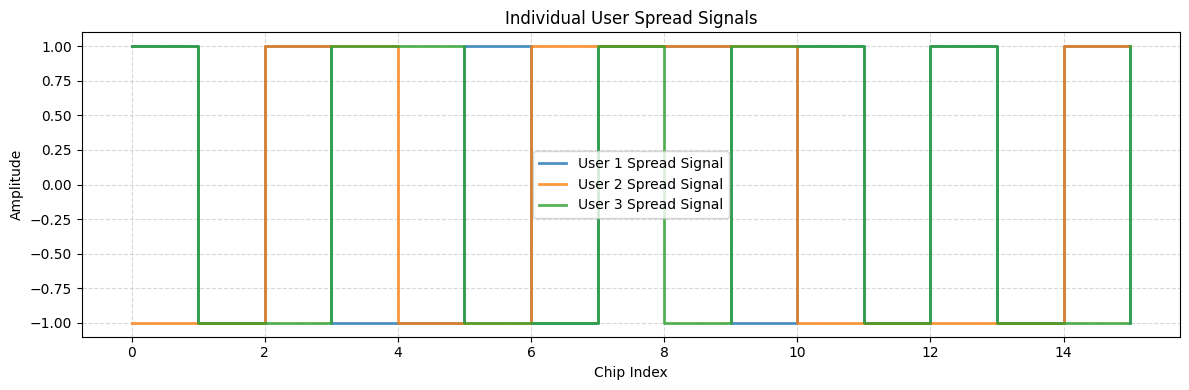

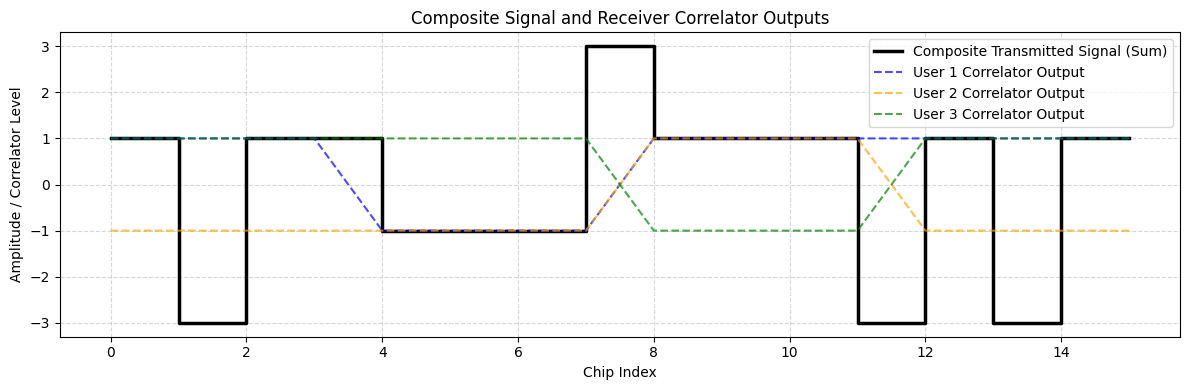

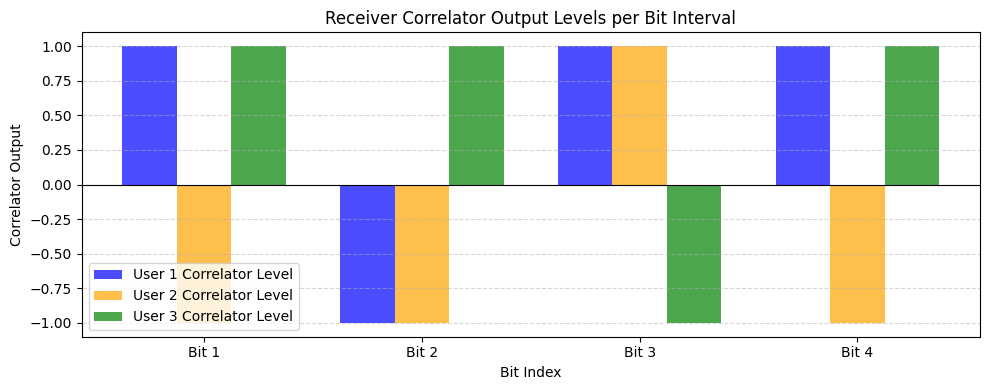

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup Parameters and Orthogonal Walsh codes of length 4
W = np.array([
    [ 1,  1,  1,  1],
    [ 1, -1,  1, -1],
    [ 1,  1, -1, -1],
    [ 1, -1, -1,  1]
])
bits = {1: [1, 0, 1, 1], 2: [0, 0, 1, 0], 3: [1, 1, 0, 1]}  # Three users
L = W.shape[1]
nbits = 4

def bpsk(b):
    return 2 * np.array(b) - 1

# 2. Transmission: Compute Spreading & Composite Signal
tx = np.zeros(nbits * L)
spread_signals = {}

for u, b in bits.items():
    spread = np.repeat(bpsk(b), L) * np.tile(W[u], nbits)
    spread_signals[u] = spread
    tx += spread

print("Composite transmitted signal:\n", tx.astype(int))

# 3. Receiver: Despreading and Correlator Output calculation
user_corrs = {}
print("\nDespreading at receiver:")
for u, b in bits.items():
    corr = (tx * np.tile(W[u], nbits)).reshape(nbits, L).sum(axis=1) / L
    user_corrs[u] = corr
    rec = (corr > 0).astype(int)
    print(f"User {u} correlator: {corr} -> bits {rec.tolist()} {'OK' if rec.tolist() == b else 'ERROR'}")

# 4. Visualization 1: Individual User Spread Signals
plt.figure(figsize=(12, 4))
for u, spread in spread_signals.items():
    plt.step(range(len(spread)), spread, label=f'User {u} Spread Signal', where='post', alpha=0.8, linewidth=2)
plt.title('Individual User Spread Signals')
plt.xlabel('Chip Index')
plt.ylabel('Amplitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 5. Visualization 2: Composite Signal & Despreading Verification
plt.figure(figsize=(12, 4))
plt.step(range(len(tx)), tx, label='Composite Transmitted Signal (Sum)', color='black', where='post', linewidth=2.5)

colors = {1: 'blue', 2: 'orange', 3: 'green'}
for u, corr in user_corrs.items():
    corr_stretched = np.repeat(corr, L)
    plt.plot(range(len(corr_stretched)), corr_stretched, '--', label=f'User {u} Correlator Output', color=colors[u], alpha=0.7)

plt.title('Composite Signal and Receiver Correlator Outputs')
plt.xlabel('Chip Index')
plt.ylabel('Amplitude / Correlator Level')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 6. Visualization 3: Bar Chart of Correlator Outputs per Bit Interval
plt.figure(figsize=(10, 4))
x = np.arange(nbits)
width = 0.25

plt.bar(x - width, user_corrs[1], width, label='User 1 Correlator Level', color='blue', alpha=0.7)
plt.bar(x, user_corrs[2], width, label='User 2 Correlator Level', color='orange', alpha=0.7)
plt.bar(x + width, user_corrs[3], width, label='User 3 Correlator Level', color='green', alpha=0.7)

plt.axhline(0, color='black', linewidth=0.8, linestyle='-')
plt.title('Receiver Correlator Output Levels per Bit Interval')
plt.xlabel('Bit Index')
plt.ylabel('Correlator Output')
plt.xticks(x, [f'Bit {i+1}' for i in range(nbits)])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()